# Housing price regression

The final model uses SquareFootage and SchoolRating (training R² 0.354). The size-only fit (R² 0.295) is a comparison. Training MSE is 14,797,731,172.37 and test MSE is 13,350,444,375.96, in dollars squared.

[Housing model report](../docs/housing-model-results.md)

In [2]:

#Importing Libraries
import pandas as pd # pandas for data manipulation and analysis
import seaborn as sns # seaborn for data visualization
import matplotlib.pyplot as plt # matplotlib for data visualization
import statsmodels.api as sm # statsmodels for statistical modeling
from sklearn.linear_model import LinearRegression # sklearn for machine learning
from sklearn.model_selection import train_test_split # sklearn for splitting data into training and testing sets
from sklearn.metrics import mean_squared_error # sklearn for evaluating model performance
from statsmodels.stats.outliers_influence import variance_inflation_factor # statsmodels for calculating VIF

file_path = r"../data/housing_data.csv"

df = pd.read_csv(file_path)

print(df.columns)

Index(['ID', 'Price', 'SquareFootage', 'NumBathrooms', 'NumBedrooms',
       'BackyardSpace', 'CrimeRate', 'SchoolRating', 'AgeOfHome',
       'DistanceToCityCenter', 'EmploymentRate', 'PropertyTaxRate',
       'RenovationQuality', 'LocalAmenities', 'TransportAccess', 'Fireplace',
       'HouseColor', 'Garage', 'Floors', 'Windows', 'PreviousSalePrice',
       'IsLuxury'],
      dtype='object')


In [3]:
df

,ID,Price,SquareFootage,NumBathrooms,NumBedrooms,BackyardSpace,CrimeRate,SchoolRating,AgeOfHome,DistanceToCityCenter,...,RenovationQuality,LocalAmenities,TransportAccess,Fireplace,HouseColor,Garage,Floors,Windows,PreviousSalePrice,IsLuxury
0,4922,255614.8992,566.62,1.000000,4,779.42,20.56,5.62,39.46,10.08,...,4.93,4.44,4.55,Yes,Blue,No,1,13,181861.54230,0
1,5009,155586.0947,1472.34,1.000000,2,656.13,15.62,5.63,40.51,7.89,...,4.08,5.56,6.83,No,Green,No,1,17,50042.59757,0
2,4450,131050.8324,550.00,1.779354,3,754.57,12.47,9.20,48.38,23.74,...,4.26,8.07,8.48,Yes,Green,Yes,2,34,48400.34440,0
3,1070,151361.7125,941.81,2.035254,2,439.59,22.22,7.08,94.67,5.22,...,4.45,5.00,6.27,Yes,Red,No,1,14,84594.12145,0
4,400,113167.6128,550.00,1.064644,3,353.03,8.28,5.93,16.80,43.13,...,3.36,5.46,6.99,No,White,Yes,1,21,22934.59654,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6995,6987,307821.1758,550.00,2.111022,4,892.35,11.89,7.97,28.18,19.23,...,4.76,3.81,6.87,No,White,Yes,1,18,241131.63070,1
6996,6995,421368.8869,1726.12,4.056115,2,943.19,34.06,5.82,90.45,17.60,...,5.31,9.84,10.00,No,White,Yes,1,18,481604.80730,1
6997,6996,473382.5348,1026.36,2.077177,5,149.31,0.10,8.81,31.79,11.59,...,4.98,7.47,2.96,No,Green,No,1,13,380555.49390,1
6998,6998,343397.9756,2218.22,1.000000,4,526.81,11.18,9.20,15.21,3.96,...,4.68,7.66,6.12,No,Blue,Yes,1,10,442610.31710,0


In [4]:
#Descriptive statistics
variable_columns = ['Price', 'SquareFootage', 'SchoolRating']
stats = df[variable_columns].describe()

# Display the results
display(stats)

,Price,SquareFootage,SchoolRating
count,7.000000e+03,7000.000000,7000.000000
mean,3.072820e+05,1048.947459,6.942923
std,1.501734e+05,426.010482,1.888148
min,8.500000e+04,550.000000,0.220000
25%,1.921075e+05,660.815000,5.650000
50%,2.793230e+05,996.320000,7.010000
75%,3.918781e+05,1342.292500,8.360000
max,1.046676e+06,2874.700000,10.000000


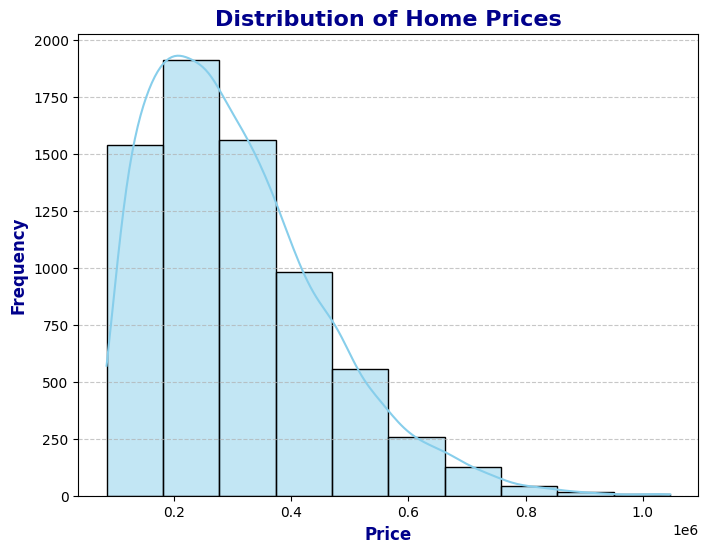

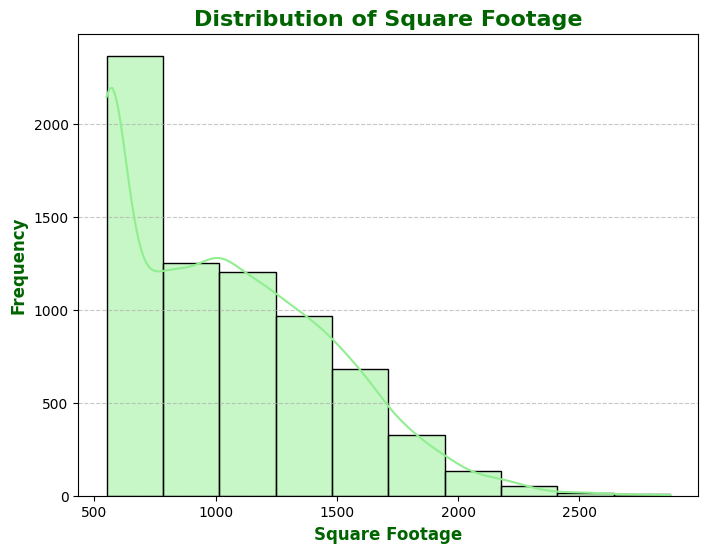

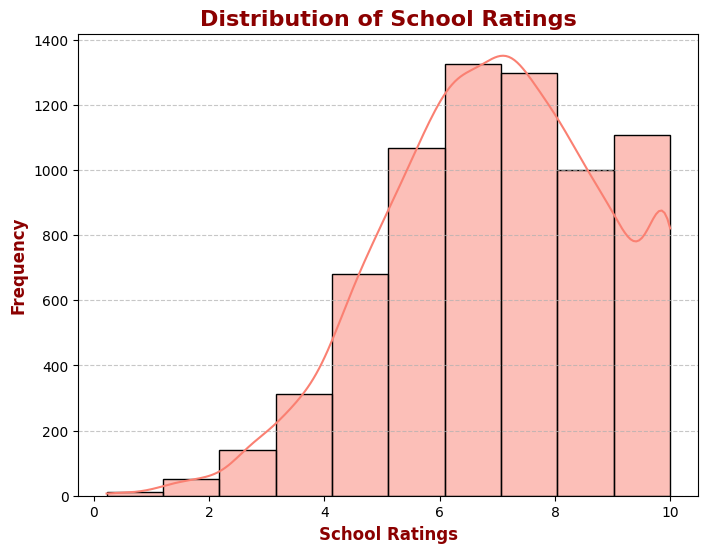

In [5]:
# Univariate visualizations

# Histogram of Price distribution
plt.figure(figsize=(8, 6))
sns.histplot(df['Price'], kde=True, bins=10, color='skyblue', edgecolor='black')
plt.title('Distribution of Home Prices', fontsize=16, fontweight='bold', color='darkblue')
plt.xlabel('Price', fontsize=12, fontweight='bold', color='darkblue')
plt.ylabel('Frequency', fontsize=12, fontweight='bold', color='darkblue')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Histogram of square Footage distribution
plt.figure(figsize=(8, 6))
sns.histplot(df['SquareFootage'], kde=True, bins=10, color='lightgreen', edgecolor='black')
plt.title('Distribution of Square Footage', fontsize=16, fontweight='bold', color='darkgreen')
plt.xlabel('Square Footage', fontsize=12, fontweight='bold', color='darkgreen')
plt.ylabel('Frequency', fontsize=12, fontweight='bold', color='darkgreen')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Histogram of school rating distribution
plt.figure(figsize=(8, 6))
sns.histplot(df['SchoolRating'], kde=True, bins=10, color='salmon', edgecolor='black')
plt.title('Distribution of School Ratings', fontsize=16, fontweight='bold', color='darkred')
plt.xlabel('School Ratings', fontsize=12, fontweight='bold', color='darkred')
plt.ylabel('Frequency', fontsize=12, fontweight='bold', color='darkred')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

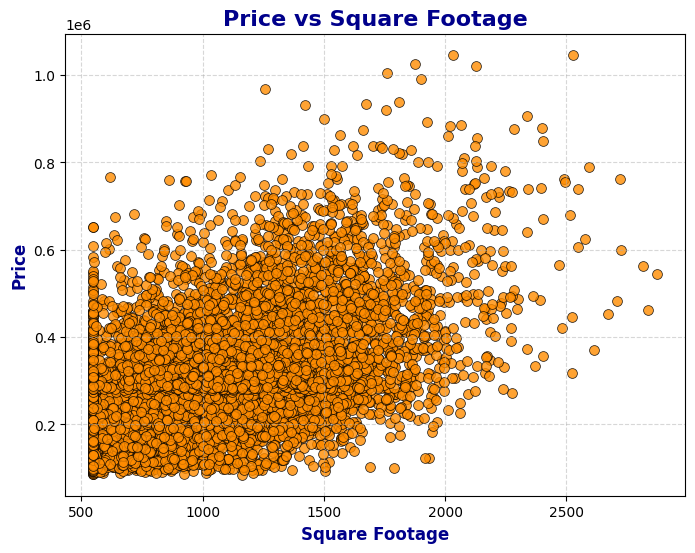

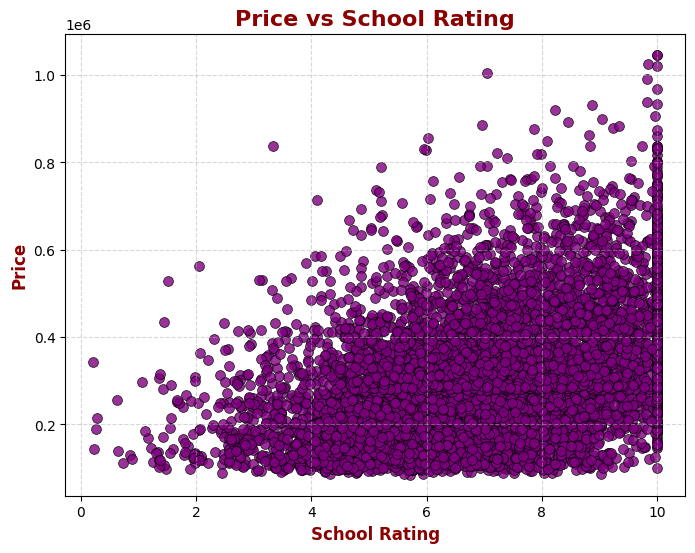

In [6]:
# Bivariate visualizations

# Scatter plot: Price vs. Square Footage
plt.figure(figsize=(8, 6))
sns.scatterplot(x='SquareFootage', y='Price', data=df, color='darkorange', s=50, edgecolor='black', alpha=0.8)
plt.title('Price vs Square Footage', fontsize=16, fontweight='bold', color='darkblue')
plt.xlabel('Square Footage', fontsize=12, fontweight='bold', color='darkblue')
plt.ylabel('Price', fontsize=12, fontweight='bold', color='darkblue')
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.show()

# Scatter plot: Price vs. School Rating
plt.figure(figsize=(8, 6))
sns.scatterplot(x='SchoolRating', y='Price', data=df, color='purple', s=50, edgecolor='black', alpha=0.8)
plt.title('Price vs School Rating', fontsize=16, fontweight='bold', color='darkred')
plt.xlabel('School Rating', fontsize=12, fontweight='bold', color='darkred')
plt.ylabel('Price', fontsize=12, fontweight='bold', color='darkred')
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.show()

In [7]:
#  Split the data into two datasets, with a larger percentage assigned to the training dataset and a smaller percentage assigned to the test data set. Provide the files.

# Only use the relevant variables
variables = ['Price', 'SquareFootage', 'SchoolRating']
df_subset = df[variables]

# Split into train (80%) and test (20%) sets
train_df, test_df = train_test_split(df_subset, test_size=0.2, random_state=42)

# Save as CSV
train_df.to_csv("train_data.csv", index=False)
test_df.to_csv("test_data.csv", index=False)


In [8]:
#  Use the training dataset to create and perform a regression model using regression as a statistical method.

# Define X and y from the training data
X_train = train_df[['SquareFootage', 'SchoolRating']]
y_train = train_df['Price']

# Add constant for intercept
X_train_const = sm.add_constant(X_train)

# Fit the regression model
model = sm.OLS(y_train, X_train_const).fit()

# Show full summary
model_summary = model.summary()
print(model_summary)


                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.354
Model:                            OLS   Adj. R-squared:                  0.353
Method:                 Least Squares   F-statistic:                     1531.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):               0.00
Time:                        07:58:14   Log-Likelihood:                -73516.
No. Observations:                5600   AIC:                         1.470e+05
Df Residuals:                    5597   BIC:                         1.471e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -8618.3923   6639.861     -1.298

In [9]:
# Optimize Model

# Start with both variables
X_full = train_df[['SquareFootage', 'SchoolRating']]
y = train_df['Price']
X_full_const = sm.add_constant(X_full)
full_model = sm.OLS(y, X_full_const).fit()

# Stepwise check: Look at p-values
print(full_model.summary())

# Comparison only: SchoolRating is significant and remains in the final model.
X_reduced = train_df[['SquareFootage']]
X_reduced_const = sm.add_constant(X_reduced)
reduced_model = sm.OLS(y, X_reduced_const).fit()

# Compare both models
print("\nReduced Model:")
print(reduced_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.354
Model:                            OLS   Adj. R-squared:                  0.353
Method:                 Least Squares   F-statistic:                     1531.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):               0.00
Time:                        07:58:14   Log-Likelihood:                -73516.
No. Observations:                5600   AIC:                         1.470e+05
Df Residuals:                    5597   BIC:                         1.471e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -8618.3923   6639.861     -1.298

In [10]:
# Mean Squared Error (MSE)

# Predict on training data using the optimized model
y_train_pred = full_model.predict(X_full_const)

# Calculate MSE
mse = mean_squared_error(y, y_train_pred)
print("Mean Squared Error (MSE) on training set:", mse)

Mean Squared Error (MSE) on training set: 14797731172.371107


In [11]:
# Model Accuracy

# Prepare test data
X_test = test_df[['SquareFootage', 'SchoolRating']]
y_test = test_df['Price']
X_test_const = sm.add_constant(X_test)

# Make predictions using the trained (optimized) model
y_test_pred = full_model.predict(X_test_const)

# Calculate MSE on test data
mse_test = mean_squared_error(y_test, y_test_pred)
print("Mean Squared Error (MSE) on test set:", mse_test)

Mean Squared Error (MSE) on test set: 13350444375.963688


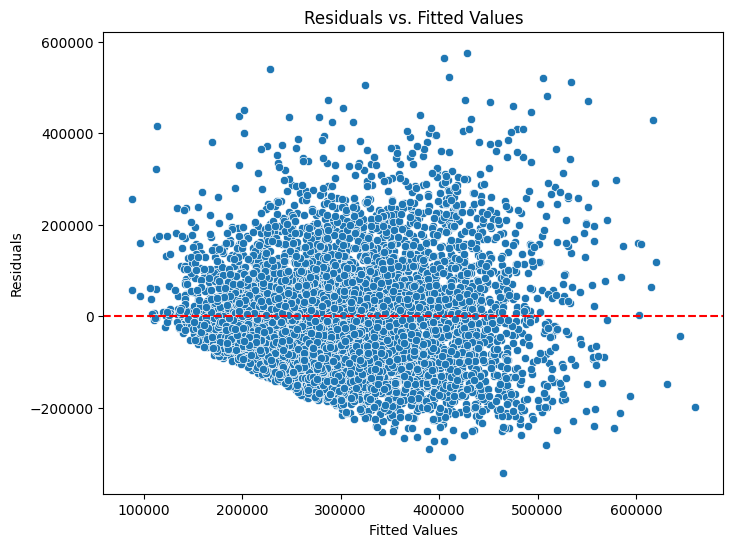

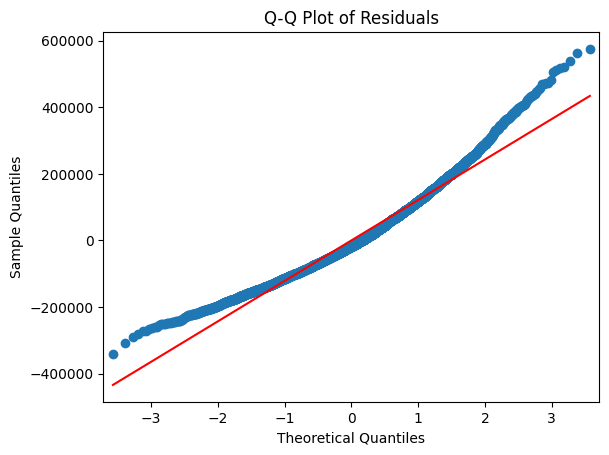

         feature       VIF
0  SquareFootage  1.087719
1   SchoolRating  1.087719


In [12]:
# 1. Linearity + Homoscedasticity (plot residuals)
residuals = full_model.resid
fitted = full_model.fittedvalues

plt.figure(figsize=(8,6))
sns.scatterplot(x=fitted, y=residuals)
plt.axhline(0, linestyle='--', color='red')
plt.title("Residuals vs. Fitted Values")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.show()

# 2. Normality of Residuals
sm.qqplot(residuals, line='s')
plt.title("Q-Q Plot of Residuals")
plt.show()

# 3. Multicollinearity (VIF)
X = train_df[['SquareFootage', 'SchoolRating']]
X_const = sm.add_constant(X)

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X_const.values, i+1) for i in range(X.shape[1])]
print(vif_data)
